# 5 · Undistortion and measuring in millimetres

The goal of the project: measure flat objects lying on the board plane, in mm, with a single webcam.
One image only gives a **ray** per pixel, never a depth. The board provides the missing knowledge: `solvePnP` gives its pose (the plane), and each ray is intersected with that plane.

`calib.geometry.image_to_board_plane`:
1. `pixel_to_normalized`: remove distortion and apply $K^{-1}$ (`cv2.undistortPoints`);
2. ray in the board frame: centre $C = -R^\mathsf T t$, direction $R^\mathsf T (x, y, 1)^\mathsf T$;
3. `ray_plane_intersection` with $Z = 0$: $\lambda = n^\mathsf T(P_0 - C) / n^\mathsf T d$ (rays parallel to the plane give NaN).

> The webcam sections need captures in `data/webcam/` (mine are not published because they show my face). The saved outputs show my results; every synthetic section runs as is.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from testbench import gt

PATTERN = (9, 6)                              # inner corners of the checkerboard
WEBCAM = ROOT / "data" / "webcam"             # my captures (not published: they show my face)
FIG = ROOT / "docs" / "images"                # figures used in the README
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.precision", 3)

In [2]:
import time
from calib.board import object_points
from calib.detect import find_corners
from calib.calibrate import calibrate
from calib.geometry import image_to_board_plane
from calib.io_yaml import load_calibration

K, dist, size = load_calibration(ROOT / "calibration.yaml")      # written in notebook 3
print("webcam K:\n", K.round(1), "\ndist:", dist.round(4), "\nsize:", size)

webcam K:
 [[1.2498e+03 0.0000e+00 9.2580e+02]
 [0.0000e+00 1.2490e+03 5.5590e+02]
 [0.0000e+00 0.0000e+00 1.0000e+00]] 
dist: [ 5.590e-02 -2.240e-01 -0.000e+00  1.000e-04  1.812e-01] 
size: (1920, 1080)


## 5.1 Real-time undistortion

The undistortion map (for every output pixel: where to read in the distorted input) depends only on $K$ and the distortion. `scripts/undistort_live.py` computes it once with `initUndistortRectifyMap`; each frame is then a single `remap`.

In [3]:
frame = cv2.imread(str(sorted((WEBCAM / "calib_1920x1080").glob("*.png"))[0]))
maps = cv2.initUndistortRectifyMap(K, dist, None, K, size, cv2.CV_16SC2)     # once

def ms_per_frame(fn, n=30):
    t0 = time.perf_counter()
    for _ in range(n):
        fn()
    return (time.perf_counter() - t0) / n * 1000

t_und = ms_per_frame(lambda: cv2.undistort(frame, K, dist))
t_map = ms_per_frame(lambda: cv2.remap(frame, *maps, cv2.INTER_LINEAR))
print(f"1920x1080: cv2.undistort {t_und:.1f} ms/frame | precomputed maps + remap {t_map:.1f} ms/frame "
      f"({t_und / t_map:.0f}x faster)")

1920x1080: cv2.undistort 31.1 ms/frame | precomputed maps + remap 2.9 ms/frame (11x faster)


The effect is easiest to see on the synthetic camera, which has strong barrel distortion ($k_1 = -0.30$). The red line joins the first and last corner of one board edge: the edge is curved in the original (up to 9 px away from the line) and straight after undistortion.

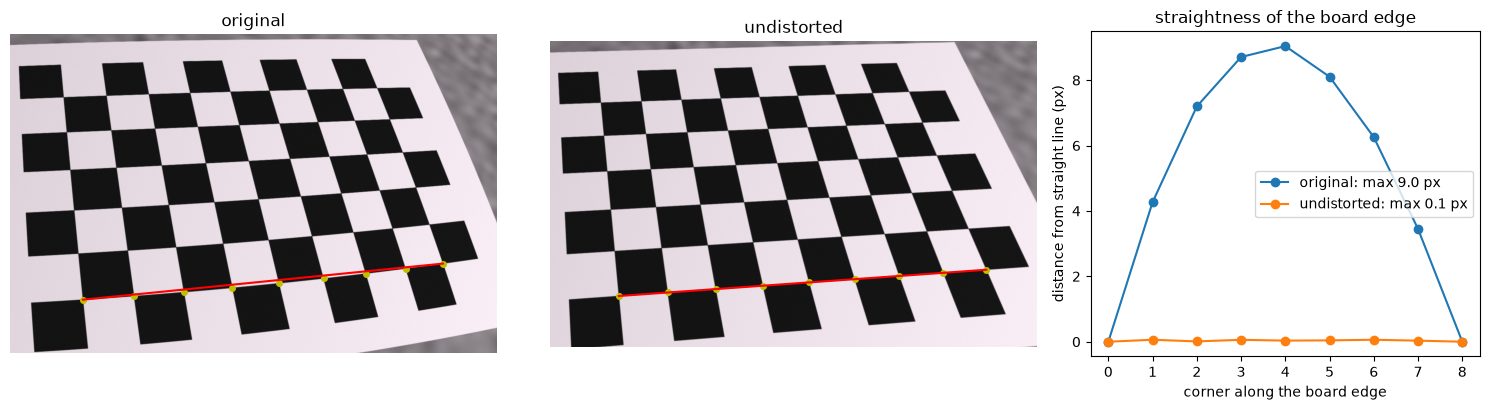

In [4]:
from calib.detect import fix_orientation
Ks, ds, _ = gt.camera("full")
img = cv2.imread(str(gt.data_dir("full") / "img_19.jpg"))
und = cv2.undistort(img, Ks, ds)

def board_grid(im):
    gray = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)
    return fix_orientation(gray, find_corners(gray, PATTERN), PATTERN).reshape(6, 9, 2)

def deviation(row):
    """Distance (px) of each corner from the straight line through the row's end points."""
    d = row[-1] - row[0]
    n = np.array([-d[1], d[0]]) / np.linalg.norm(d)
    return np.abs((row - row[0]) @ n)

grids = {"original": board_grid(img), "undistorted": board_grid(und)}
edges = lambda g: [g[0], g[-1], g[:, 0], g[:, -1]]
k = int(np.argmax([deviation(e).max() for e in edges(grids["original"])]))   # most curved edge

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), gridspec_kw=dict(width_ratios=[1, 1, 0.8]))
for ax, (title, im) in zip(axes, [("original", img), ("undistorted", und)]):
    g = grids[title]
    row = edges(g)[k]
    (x0, y0), (x1, y1) = g.reshape(-1, 2).min(0) - 150, g.reshape(-1, 2).max(0) + 150
    ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); ax.set_xlim(x0, x1); ax.set_ylim(y1, y0)
    ax.plot(row[:, 0], row[:, 1], "y.", ms=8); ax.plot(row[[0, -1], 0], row[[0, -1], 1], "r-", lw=1.5)
    ax.set_title(title); ax.axis("off")
    axes[2].plot(deviation(row), "o-", label=f"{title}: max {deviation(row).max():.1f} px")
axes[2].set_xlabel("corner along the board edge"); axes[2].set_ylabel("distance from straight line (px)")
axes[2].set_title("straightness of the board edge"); axes[2].legend()
fig.tight_layout(); fig.savefig(FIG / "undistortion.png", dpi=110); plt.show()

## 5.2 Measuring the bank card (synthetic, known truth)

A credit card (ISO 7810: 85.60 × 53.98 mm) lies on the board plane. Its corners are rounded, so I measure between the **midpoints of opposite edges**. The board pose comes from my own detected corners (`solvePnP`), not from the ground truth.

In [5]:
objp25 = object_points(*PATTERN, 25.0)
rows = []
for app in ["app_01_top.jpg", "app_02_oblique.jpg", "app_03_side.jpg"]:
    gray = cv2.imread(str(gt.data_dir("apps") / app), cv2.IMREAD_GRAYSCALE)
    c = find_corners(gray, PATTERN)
    _, rvec, tvec = cv2.solvePnP(objp25, c, Ks, ds)
    m = image_to_board_plane(gt.card_edge_midpoints(app), Ks, ds, rvec, tvec)
    rows.append({"view": app[7:-4], "width (mm)": np.linalg.norm(m[1] - m[0]),
                 "height (mm)": np.linalg.norm(m[3] - m[2])})
pd.DataFrame(rows).assign(**{"width error": lambda d: d["width (mm)"] - 85.60,
                             "height error": lambda d: d["height (mm)"] - 53.98}).round(2)

,view,width (mm),height (mm),width error,height error
0,top,85.60,53.98,-0.00,-0.0
1,oblique,85.60,53.98,0.00,0.0
2,side,85.58,53.98,-0.02,0.0


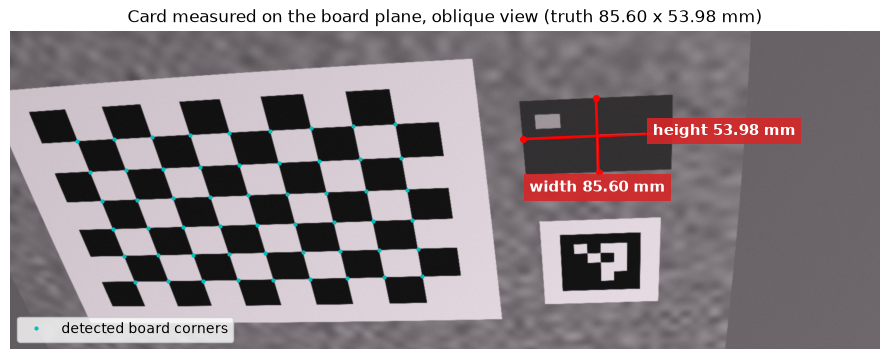

In [6]:
app = "app_02_oblique.jpg"
img = cv2.cvtColor(cv2.imread(str(gt.data_dir("apps") / app)), cv2.COLOR_BGR2RGB)
c = find_corners(cv2.cvtColor(img, cv2.COLOR_RGB2GRAY), PATTERN)
_, rvec, tvec = cv2.solvePnP(objp25, c, Ks, ds)
p = gt.card_edge_midpoints(app)
m = image_to_board_plane(p, Ks, ds, rvec, tvec)

fig, ax = plt.subplots(figsize=(9, 5.2))
ax.imshow(img); ax.plot(*c.reshape(-1, 2).T, "c.", ms=4, label="detected board corners")
offsets = {"width": (0, -40), "height": (40, 0)}
for (i, j), label in [((0, 1), "width"), ((2, 3), "height")]:
    ax.plot(p[[i, j], 0], p[[i, j], 1], "r-o", lw=2, ms=4)
    ax.annotate(f"{label} {np.linalg.norm(m[j] - m[i]):.2f} mm", p[[i, j]].mean(0), xytext=offsets[label],
                textcoords="offset points", ha="left" if label == "height" else "center", color="w",
                fontsize=11, weight="bold", bbox=dict(fc="tab:red", ec="none", alpha=0.9),
                arrowprops=dict(arrowstyle="-", color="tab:red"))
pts_all = np.vstack([c.reshape(-1, 2), p])
(x0, y0), (x1, y1) = pts_all.min(0) - 120, pts_all.max(0) + 120
ax.set_xlim(x0, x1 + 250); ax.set_ylim(y1, y0); ax.axis("off"); ax.legend(loc="lower left")
ax.set_title("Card measured on the board plane, oblique view (truth 85.60 x 53.98 mm)")
fig.tight_layout(); fig.savefig(FIG / "measurement.png", dpi=100, bbox_inches="tight"); plt.show()

Even in the oblique and side views the error is ≤ 0.02 mm: the geometry is exact, so in practice the accuracy is limited by how precisely the points are located.

## 5.3 The webcam

**Best-case accuracy:** re-measuring the board's own corners in the measurement photos (detected → board plane) against the known grid:

In [7]:
objp_w = object_points(*PATTERN, 8.24)
rows = []
for f in sorted((WEBCAM / "apps_1920x1080").glob("*.png")):
    c = find_corners(cv2.imread(str(f), cv2.IMREAD_GRAYSCALE), PATTERN)
    if c is None:
        continue
    _, rvec, tvec = cv2.solvePnP(objp_w, c, K, dist)
    err = np.linalg.norm(image_to_board_plane(c.reshape(-1, 2), K, dist, rvec, tvec) - objp_w[:, :2], axis=1)
    rows.append({"photo": f.stem[-3:], "mean error (mm)": err.mean(), "max error (mm)": err.max(),
                 "distance (mm)": np.linalg.norm(tvec), "mm per px": np.linalg.norm(tvec) / K[0, 0]})
pd.DataFrame(rows).round(3)

,photo,mean error (mm),max error (mm),distance (mm),mm per px
0,000,0.044,0.130,236.853,0.190
1,001,0.064,0.194,270.371,0.216
2,002,0.047,0.126,293.908,0.235
3,003,0.034,0.076,296.847,0.238
4,004,0.032,0.087,320.647,0.257
5,005,0.058,0.133,310.899,0.249
6,006,0.060,0.130,303.201,0.243
7,007,0.037,0.096,238.448,0.191
8,008,0.047,0.118,198.313,0.159
9,009,0.035,0.097,240.126,0.192


Board corners land on average within 0.03–0.06 mm (max ≤ 0.2 mm) of the true grid. At 18–32 cm one pixel covers 0.14–0.26 mm, so the precision of the clicks dominates the error budget.

**Card measurement with `scripts/measure.py`** (click the middle of the left/right and top/bottom card edges):

| Photo | Width (mm) | Height (mm) | Error |
|---|---|---|---|
| card zone, 1920×1080 | 85.68 | 53.81 | +0.08 / −0.17 mm |

Target ±1 mm: met with a large margin.

## 5.4 Error budget: the card is not exactly on the board plane

The card lies on the screen glass, ≈ 0.76 mm above the displayed board. The synthetic camera shows how a height $h$ above the plane turns into measurement error:

In [8]:
from testbench._render import SceneLayout
mid = SceneLayout().card_edge_midpoints()                      # true 3D midpoints on Z = 0 (mm)
rows = []
for app in ["app_01_top.jpg", "app_02_oblique.jpg"]:
    rv, tv = gt.pose(f"apps/{app}")
    for h in [0.76, 5.0, 20.0]:
        lifted = mid - [0, 0, h]                                 # towards the camera (board z axis points away)
        px, _ = cv2.projectPoints(lifted, rv, tv, Ks, ds)
        m = image_to_board_plane(px.reshape(-1, 2), Ks, ds, rv, tv)
        rows.append({"view": app[7:-4], "height above plane (mm)": h,
                     "width error (mm)": np.linalg.norm(m[1] - m[0]) - 85.60,
                     "height error (mm)": np.linalg.norm(m[3] - m[2]) - 53.98})
pd.DataFrame(rows).round(2)

,view,height above plane (mm),width error (mm),height error (mm)
0,top,0.76,0.10,0.07
1,top,5.00,0.69,0.44
2,top,20.00,2.84,1.79
3,oblique,0.76,0.13,0.08
4,oblique,5.00,0.86,0.54
5,oblique,20.00,3.54,2.24


The 0.76 mm glass thickness costs ≈ 0.1 mm, negligible for ±1 mm. An object 2 cm in front of the plane would be measured several mm too large. Objects must lie on the plane, or the plane must be shifted (`plane_point = (0, 0, -h)`).

## Summary

| Criterion | Target | Result |
|---|---|---|
| RMS reprojection error | ≤ 0.5 px | 0.27 px |
| Hold-out error | ≤ 1.3 × RMS | 1.05 × RMS |
| Bank card | ± 1 mm | +0.08 / −0.17 mm |
| Undistortion speed | ≥ 20 fps | ≈ 3 ms per 1080p frame (≈ 10× faster than `cv2.undistort`) |